# Penicillium vs the published IndPenSim data

Does Penicillium reproduce the 100-batch IndPenSim data set of Goldrick et al. (2019) statistically?

Requirements:

* the 100-batch data set (Mendeley Data, doi:10.17632/pdnjz7zz5x.1, CC BY 4.0), downloaded and converted on
  first use by `validation/indpensim_100_batches.py` (500 MB download, 1 GB cache);
* about 2 minutes on 8 cores, once the data set is cached.


In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import penicillium
from penicillium import Fault

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "notebooks" / "output"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Penicillium {penicillium.__version__}")

Penicillium 0.1.0.dev0


## Campaigns with the published structure

MATLAB's random generator cannot be reproduced in Python, so batch *n* here cannot be batch *n* of the data set.
Instead we simulate campaigns with the data set's structure: for each published batch, the same control strategy
(1-30 recipe driven, 31-60 operator controlled, 61-90 advanced control of PAA, 91-100 faults), the same length
and the same fault, the fault type being read from its signature in the recorded inputs. Three replicates give 300
simulated batches; then we compare distributions.

In [2]:
sys.path.insert(0, str(ROOT / "validation"))
import compare_100_batches as cmp
from indpensim_100_batches import load_process, load_statistics

published = load_process()  # downloads and converts the data set on first use
plan = cmp.published_batches(published, load_statistics())
print(f"{published['batch_id'].nunique()} published batches, {len(published):,} samples")
print(
    "fault types inferred from the inputs:",
    ", ".join(f"{r.batch_id}: {Fault(r.fault).name}" for r in plan[plan.strategy == "fault"].itertuples()),
)

t0 = time.perf_counter()
sim_summary, sim_results = cmp.simulate(plan, replicates=3, jobs=os.cpu_count())
print(f"simulated {len(sim_summary)} batches in {time.perf_counter() - t0:.0f} s on {os.cpu_count()} processes")

100 published batches, 113,935 samples
fault types inferred from the inputs: 91: SUBSTRATE_FEED, 92: BASE_FLOW, 93: COOLANT_FLOW, 94: AERATION, 95: SUBSTRATE_FEED, 96: COOLANT_FLOW, 97: SUBSTRATE_FEED, 98: BASE_FLOW, 99: AERATION, 100: AERATION


simulated 300 batches in 79 s on 8 processes


In [3]:
from scipy import stats

rows = []
for strategy in cmp.STRATEGIES:
    p = plan[plan.strategy == strategy]
    s = sim_summary[sim_summary.strategy == strategy]
    rows.append(
        {
            "strategy": strategy,
            "batches (published / simulated)": f"{len(p)} / {len(s)}",
            "published yield [kg]": f"{p.yield_kg.mean():.0f} ± {p.yield_kg.std():.0f}",
            "simulated yield [kg]": f"{s.yield_kg.mean():.0f} ± {s.yield_kg.std():.0f}",
            "KS p-value (yield)": stats.ks_2samp(p.yield_kg, s.yield_kg).pvalue,
            "published final P [g/L]": f"{p.final_P.mean():.1f} ± {p.final_P.std():.1f}",
            "simulated final P [g/L]": f"{s.final_P.mean():.1f} ± {s.final_P.std():.1f}",
            "KS p-value (final P)": stats.ks_2samp(p.final_P, s.final_P).pvalue,
        }
    )
pd.DataFrame(rows).set_index("strategy").round(2)

,batches (published / simulated),published yield [kg],simulated yield [kg],KS p-value (yield),published final P [g/L],simulated final P [g/L],KS p-value (final P)
strategy,,,,,,,
recipe,30 / 90,2913 ± 768,2868 ± 840,0.93,24.3 ± 8.7,23.7 ± 7.9,0.87
operator,30 / 90,2833 ± 680,2822 ± 848,0.31,21.5 ± 8.0,22.6 ± 8.0,0.54
apc,30 / 90,3484 ± 308,3356 ± 324,0.10,29.4 ± 2.7,29.1 ± 2.2,0.04
fault,10 / 30,2600 ± 1200,2061 ± 1099,0.63,14.4 ± 11.0,16.5 ± 10.2,0.48


A Kolmogorov-Smirnov p-value above 0.05 means the test finds no difference between the published and the
simulated distribution. The trajectories: share of published samples inside the simulated 5-95 % band at the same
time (ideal: about 0.9).

In [4]:
envelopes = cmp.envelope_table(published, sim_summary, sim_results)
envelopes.pivot(index="channel", columns="strategy", values="coverage").loc[cmp.CHANNELS, list(cmp.STRATEGIES)].round(2)

strategy,recipe,operator,apc,fault
channel,,,,
P,0.88,0.87,0.93,0.81
V,0.83,0.91,0.83,0.80
S,0.91,0.85,0.91,0.86
DO2,0.91,0.91,0.95,0.92
T,0.89,0.88,0.89,0.80
pH,0.90,0.91,0.88,0.85
CO2outgas,0.89,0.92,0.89,0.79
OUR,0.89,0.89,0.92,0.80
Fs,1.00,0.99,1.00,1.00


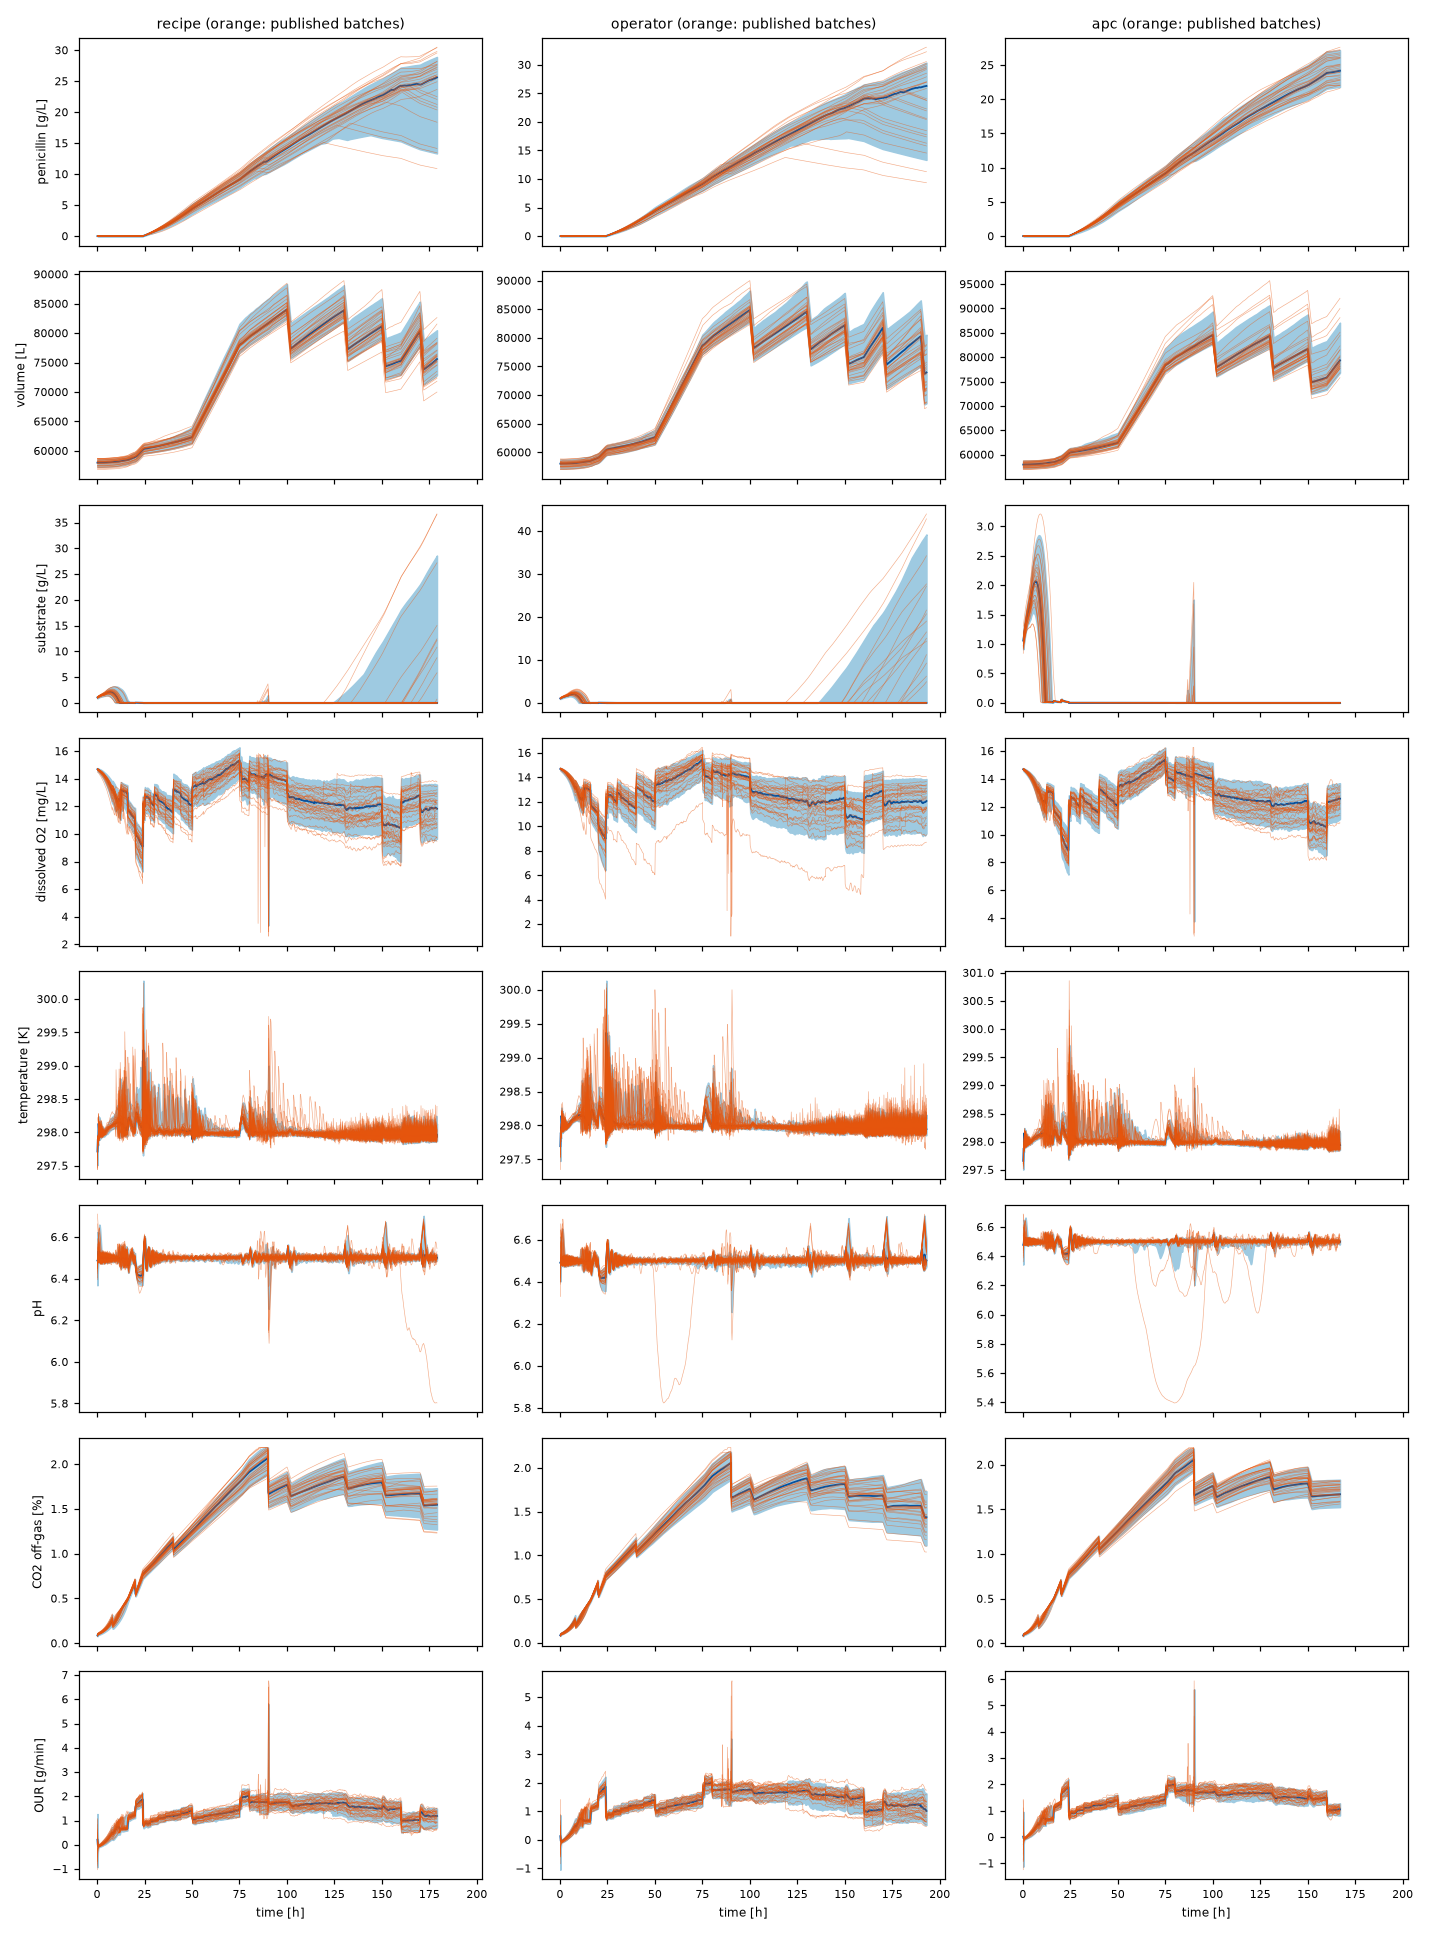

In [5]:
figure = OUT / "published_vs_simulated.png"
cmp.plot(published, sim_summary, sim_results, figure)
plt.close("all")
display(Image(filename=str(figure)))

In [6]:
ks = {r["strategy"]: r["KS p-value (yield)"] for r in rows}
print(
    "Yield distributions vs the 100 published batches, KS p-values "
    + ", ".join(f"{k} {v:.2f}" for k, v in ks.items())
    + "."
)

Yield distributions vs the 100 published batches, KS p-values recipe 0.93, operator 0.31, apc 0.10, fault 0.63.
